# NB5b (3/3) — foundation models on the validation units: scores and settings (development)

D23, D59; guide §5.4 rows A6a (Chronos-2) and A6b (TimesFM 2.5). Each run of the grid is composed with the frozen prior and scored on exactly NB5a's slots (`r1_score.score`). **Setting per model (rule fixed before any score, D59):** the lowest median nRMSE at 1 h over the 10 units. The chosen settings are compared with the 5-seed ensembles of LightGBM, PVSetFormer (the candidate V9, D60) and TimeXer on the same slots (paired by unit). Writes `results/nb5b_fm/` with `fm_config_part2d.yaml`.

In [1]:
import os, sys, time, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / 'tools'))
from pvcold import config as C, audit as A, forecast as FC
import r1_score as R                      # NB5a context and slots (D37)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
t0 = time.time()
from scipy.stats import wilcoxon
import yaml
ctx = R.load_context()
INP, RUNS, VD = C.RESULTS / 'nb5b_inputs', C.RESULTS / 'nb5b_runs', C.RESULTS / 'nb5c_variants'
man = json.loads((INP / 'inputs_manifest.json').read_text())
GRID = [('chronos2', 336, 'full'), ('chronos2', 336, 'none'), ('chronos2', 1344, 'full'), ('chronos2', 1344, 'none'), ('timesfm25', 336, 'full'), ('timesfm25', 336, 'none'), ('timesfm25', 1344, 'full'), ('timesfm25', 1344, 'none')]
REFS = {'LightGBM': 'LGB_seeds', 'PVSetFormer': 'V9_5s', 'TimeXer': 'TX1_5s'}
info = {}
for model, L, cov in GRID:
    s = f'{model}_c{L}_{cov}'
    info[s] = json.loads((RUNS / f'{s}.json').read_text())
    assert info[s]['inputs_sha256'] == man['sha256'], f'{s} was run on other inputs'
    assert info[s]['limit'] == 0, f'{s} is a smoke test'
print(pd.DataFrame({s: {k: i[k] for k in ('model', 'context', 'cov', 'device', 'runtime_s', 'n_rows')} for s, i in info.items()}).T)

                          model context   cov device runtime_s  n_rows
chronos2_c336_full     chronos2     336  full   cuda    1034.8  184353
chronos2_c336_none     chronos2     336  none   cuda      86.0  184353
chronos2_c1344_full    chronos2    1344  full   cuda    3657.6  184353
chronos2_c1344_none    chronos2    1344  none   cuda     282.3  184353
timesfm25_c336_full   timesfm25     336  full   cuda     279.7  184353
timesfm25_c336_none   timesfm25     336  none   cuda     171.9  184353
timesfm25_c1344_full  timesfm25    1344  full   cuda     735.5  184353
timesfm25_c1344_none  timesfm25    1344  none   cuda     569.5  184353


## Scores of every setting on NB5a's slots

In [2]:
rows = []
for s, i in info.items():
    fc = pd.read_parquet(RUNS / f'{s}.parquet')
    sc = R.score(fc, ctx)                       # asserts every NB5a slot is forecast
    sc = sc[sc.seed == 1].assign(setting=s, model=i['model'], context=i['context'], cov=i['cov'])
    rows.append(sc)
SC = pd.concat(rows, ignore_index=True)
MED = SC.groupby(['setting', 'model', 'context', 'cov', 'h'])[R.METRICS].median().reset_index()
print(MED.pivot_table(index=['model', 'context', 'cov'], columns='h', values='nRMSE').round(4))

h                           1       2       4       8       16      24
model     context cov                                                 
chronos2  336     full  0.1307  0.1552  0.1795  0.2067  0.2223  0.2029
                  none  0.1305  0.1551  0.1817  0.2092  0.2300  0.2116
          1344    full  0.1297  0.1542  0.1776  0.2031  0.2192  0.2000
                  none  0.1298  0.1540  0.1783  0.2030  0.2218  0.2018
timesfm25 336     full  0.1299  0.1553  0.1801  0.2090  0.2255  0.2066
                  none  0.1292  0.1548  0.1806  0.2094  0.2263  0.2072
          1344    full  0.1299  0.1569  0.1806  0.2080  0.2258  0.2067
                  none  0.1291  0.1546  0.1790  0.2047  0.2220  0.2045


## The setting per model (lowest median nRMSE at 1 h)

In [3]:
H1 = C.PRIMARY_HORIZON
m1 = MED[MED.h == H1].sort_values('nRMSE')
CHOSEN = {m: g.iloc[0]['setting'] for m, g in m1.groupby('model')}
print(m1[['setting', 'nRMSE', 'CRPS', 'PICP80']].to_string(index=False)); print('chosen:', CHOSEN)

             setting    nRMSE     CRPS   PICP80
 chronos2_c1344_full 0.177550 0.090574 0.690663
 chronos2_c1344_none 0.178281 0.090994 0.704836
timesfm25_c1344_none 0.179008 0.091398 0.731255
  chronos2_c336_full 0.179542 0.091345 0.689542
 timesfm25_c336_full 0.180126 0.093416 0.703652
 timesfm25_c336_none 0.180556 0.092497 0.713204
timesfm25_c1344_full 0.180560 0.092659 0.717552
  chronos2_c336_none 0.181653 0.092755 0.695562
chosen: {'chronos2': 'chronos2_c1344_full', 'timesfm25': 'timesfm25_c1344_none'}


## Chosen settings against the 5-seed ensembles, paired by unit on the same slots

In [4]:
ref = {n: pd.read_csv(VD / d / 'scores.csv').query('seed == 0') for n, d in REFS.items()}
cmp = []
for m, s in CHOSEN.items():
    a = SC[SC.setting == s].set_index(['event', 'h'])
    for n, r in ref.items():
        b = r.set_index(['event', 'h']).reindex(a.index)
        assert (b['n'] == a['n']).all(), 'not the same slots'
        for h in FC.H:
            x, y = a.xs(h, level='h'), b.xs(h, level='h')
            d = (x.nRMSE - y.nRMSE).to_numpy()
            cmp.append({'fm': m, 'setting': s, 'reference': n, 'h': h, 'nRMSE_fm': x.nRMSE.median(),
                        'nRMSE_ref': y.nRMSE.median(), 'rel_pct': 100 * float(np.median(x.nRMSE / y.nRMSE - 1)),
                        'units_fm_better': int((d < 0).sum()), 'CRPS_fm': x.CRPS.median(), 'CRPS_ref': y.CRPS.median(),
                        'wilcoxon_p': float(wilcoxon(d).pvalue) if np.any(d != 0) else np.nan})
CMP = pd.DataFrame(cmp)
print(CMP[CMP.h.isin([1, 4, 24])].round(4).to_string(index=False))

       fm              setting   reference  h  nRMSE_fm  nRMSE_ref  rel_pct  units_fm_better  CRPS_fm  CRPS_ref  wilcoxon_p
 chronos2  chronos2_c1344_full    LightGBM  1    0.1297     0.1291   0.5510                1   0.0636    0.0617      0.0488
 chronos2  chronos2_c1344_full    LightGBM  4    0.1776     0.1813  -2.5210                9   0.0906    0.0937      0.0039
 chronos2  chronos2_c1344_full    LightGBM 24    0.2000     0.2180  -7.4208               10   0.1032    0.1167      0.0020
 chronos2  chronos2_c1344_full PVSetFormer  1    0.1297     0.1332  -1.1187                6   0.0636    0.0653      1.0000
 chronos2  chronos2_c1344_full PVSetFormer  4    0.1776     0.1785  -3.0090                8   0.0906    0.0945      0.4316
 chronos2  chronos2_c1344_full PVSetFormer 24    0.2000     0.2061  -3.3588               10   0.1032    0.1082      0.0020
 chronos2  chronos2_c1344_full     TimeXer  1    0.1297     0.1301   0.5876                4   0.0636    0.0619      0.2754
 chronos

## Draft figure

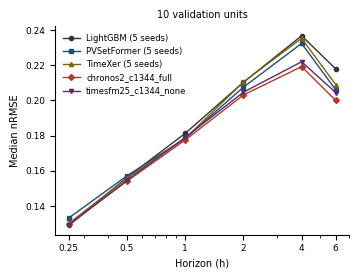

In [5]:
import matplotlib.pyplot as plt
A._style()
fig, ax = plt.subplots(1, 1, figsize=(3.6, 2.8))
hx = np.array(FC.H) * 0.25
sty = {'LightGBM': ('0.2', 'o'), 'PVSetFormer': ('#1f4e79', 's'), 'TimeXer': ('#7d6608', '^')}
for n, (c, mk) in sty.items():
    z = ref[n].groupby('h').nRMSE.median().reindex(FC.H)
    ax.plot(hx, z, color=c, marker=mk, ms=3, lw=1, label=n + ' (5 seeds)')
for (m, s), (c, mk) in zip(CHOSEN.items(), [('#b03a2e', 'D'), ('#5b2c6f', 'v')]):
    z = MED[MED.setting == s].set_index('h').nRMSE.reindex(FC.H)
    ax.plot(hx, z, color=c, marker=mk, ms=3, lw=1, label=s)
ax.set_xscale('log'); ax.set_xticks(hx); ax.set_xticklabels(['0.25', '0.5', '1', '2', '4', '6'])
ax.set_xlabel('Horizon (h)'); ax.set_ylabel('Median nRMSE'); ax.legend(frameon=False, fontsize=6)
ax.set_title('10 validation units', fontsize=7); fig.tight_layout()

## Outputs (all-or-nothing): scores, medians, comparison, configuration part 2d

In [6]:
cfg = {'part': '2d', 'decision': 'D59', 'rule': 'lowest median validation nRMSE at 1 h per model',
       'inputs_sha256': man['sha256'],
       'models': {m: {k: info[s][k] for k in ('weights', 'context', 'cov', 'grid', 'prediction_length', 'versions')}
                  | {'setting': s, 'revision': info[s].get('revision'), 'forecast_config': info[s].get('forecast_config'),
                     'xreg': info[s].get('xreg')} for m, s in CHOSEN.items()}}
CFG_TEXT = yaml.safe_dump(cfg, sort_keys=False, allow_unicode=True)
summary = {'notebook': 'NB5b_foundation', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
           'grid': [s for s in info], 'chosen': CHOSEN,
           'fm_config_sha256': hashlib.sha256(CFG_TEXT.encode()).hexdigest(),
           'median_nRMSE_1h': m1.set_index('setting')['nRMSE'].round(5).to_dict(),
           'vs_refs_1h': CMP[CMP.h == H1].set_index(['fm', 'reference'])[['rel_pct', 'units_fm_better', 'wilcoxon_p']]
                         .round(4).reset_index().to_dict('records'),
           'run_info': info}
out = A.write_outputs('nb5b_fm', {'scores': SC, 'medians': MED, 'comparison': CMP}, summary, {'fig_fm': fig},
                      texts={'fm_config_part2d.yaml': CFG_TEXT})
print(json.dumps({k: summary[k] for k in ('chosen', 'median_nRMSE_1h')}, indent=1))
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

{
 "chosen": {
  "chronos2": "chronos2_c1344_full",
  "timesfm25": "timesfm25_c1344_none"
 },
 "median_nRMSE_1h": {
  "chronos2_c1344_full": 0.17755,
  "chronos2_c1344_none": 0.17828,
  "timesfm25_c1344_none": 0.17901,
  "chronos2_c336_full": 0.17954,
  "timesfm25_c336_full": 0.18013,
  "timesfm25_c336_none": 0.18056,
  "timesfm25_c1344_full": 0.18056,
  "chronos2_c336_none": 0.18165
 }
}
written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb5b_fm | ['comparison.csv', 'figures', 'fm_config_part2d.yaml', 'medians.csv', 'scores.csv', 'summary.json']
